In [1]:
import os
import math
import yaml
from glob import glob
import numpy as np
import matplotlib.pyplot as plt
import keras
# from keras import layers
import tensorflow as tf
from tensorflow import data as tf_data
from tensorflow.keras import layers, models
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
from pprint import pprint

print("Number of available GPUs: ", len(tf.config.list_physical_devices('GPU')))

gpus = tf.config.list_physical_devices('GPU')
if not gpus:
    print("No GPUs found.")
else:
    try:
        if len(gpus) > 1:
            tf.config.set_visible_devices([gpus[0]], 'GPU')  # make only GPU 0 visible
            tf.config.experimental.set_memory_growth(gpus[0], True)
            print("Using GPU 0.")
        else:
            tf.config.set_visible_devices([gpus[0]], 'GPU')
            tf.config.experimental.set_memory_growth(gpus[0], True)
            print("Only one GPU is available. Using GPU 0.")
    except Exception as e:
        print("Failed to set visible GPU:", e)

print("Visible GPUs:", tf.config.list_physical_devices('GPU'))

2026-11-09 17:11:03.503042: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-09 17:11:03.552386: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-09 17:11:05.575269: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Number of available GPUs:  2
Using GPU 0.
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


I0000 00:00:1794265866.781666 3928532 gpu_device.cc:2411] Ignoring visible gpu device (device: 2, name: NVIDIA T400 4GB, pci bus id: 0000:e3:00.0, compute capability: 7.5) with core count: 6. The minimum required count is 8. You can adjust this requirement with the env var TF_MIN_GPU_MULTIPROCESSOR_COUNT.


The Roman cutouts are stored in `cutouts.npz`, and `index.ecsv` has one row per cutout. `load_cutouts` in `roman_cutouts.py` drops partial cutouts at the detector edge, which contain NaN pixels. It then scales each band of each remaining cutout to [0, 1] and gamma-corrects it to a median of 0.2, matching `process_image` in `organize_data.py`. `roman_load_and_predict.ipynb` uses the same function.

In [2]:
from roman_cutouts import load_cutouts

cutouts_dir = '/data/bwedig/mejiro/lens_search/cutouts/wfi01_93px'
index, data, bands = load_cutouts(cutouts_dir)
is_lens = np.array(index['is_lens'])

print(f'bands: {bands}')
print(f'lenses: {data[is_lens].shape}')
print(f'nonlenses: {data[~is_lens].shape}')

Reading from /data/bwedig/mejiro/lens_search/cutouts/wfi01_93px...
dropped 483 partial cutouts
bands: ['F106' 'F129' 'F158']
lenses: (1027, 93, 93, 3)
nonlenses: (9262, 93, 93, 3)


The dataset contains Roman cutouts, each labeled as a lens or non-lens by `is_lens`.

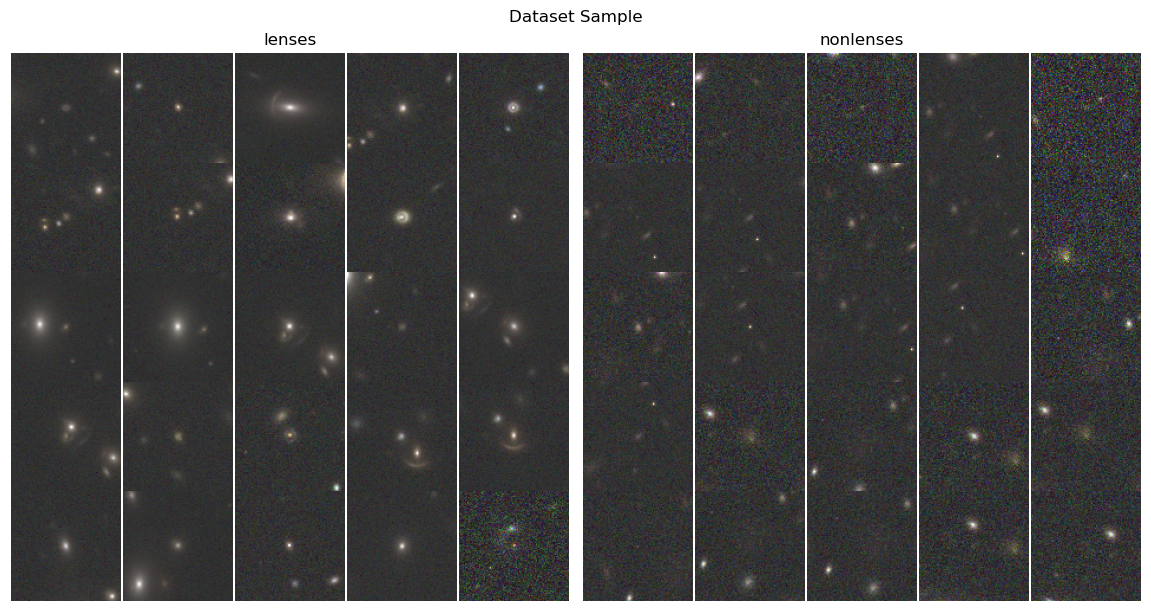

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.4, 6), constrained_layout=True)

datasets = [
    (data[is_lens], "lenses"),
    (data[~is_lens], "nonlenses"),
]

for ax, (images, title) in zip(axes.flat, datasets):
    grid_size = min(25, len(images))
    grid_rows = grid_cols = int(np.ceil(np.sqrt(grid_size)))
    for i in range(grid_size):
        row = i // grid_cols
        col = i % grid_cols
        sub_ax = ax.inset_axes([col/grid_cols, 1-row/grid_rows-1/grid_rows, 1/grid_cols, 1/grid_rows])
        sub_ax.imshow(images[i][:, :, ::-1])  # bands are (F106, F129, F158), so reverse for RGB
        sub_ax.axis("off")  # Hide axes for each image
    ax.set_title(title)
    ax.axis("off")  # Hide main axes

plt.suptitle('Dataset Sample')
plt.show()

Assign binary lens labels.

In [4]:
labels = is_lens.astype(np.uint8)
print(data.shape)
print(labels.shape)

(10289, 93, 93, 3)
(10289,)


Create a TensorFlow dataset from the arrays and labels.

In [5]:
ds = tf_data.Dataset.from_tensor_slices((data, labels))
ds = ds.shuffle(buffer_size=len(labels), reshuffle_each_iteration=False)

I0000 00:00:1794265876.708931 3928532 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9508 MB memory:  -> device: 0, name: NVIDIA RTX 6000 Ada Generation, pci bus id: 0000:31:00.0, compute capability: 8.9


Use about 95% of the shuffled rows for training and the rest for validation. The notebook does not create a separate test set.

In [6]:
# Calculate split sizes
total_size = len(labels)
train_size = int(0.95 * total_size)
val_size = total_size - train_size
print(f'end={total_size}, train={train_size}, val={val_size}')

# Split the dataset
train_ds = ds.take(train_size)
val_ds = ds.skip(train_size).take(val_size)
train_ds = train_ds.shuffle(buffer_size=train_size, reshuffle_each_iteration=True)

print(f"Train size: {train_ds.cardinality()}, Val size: {val_ds.cardinality()}")

end=10289, train=9774, val=515
Train size: 9774, Val size: 515


The training pipeline randomly flips images horizontally and vertically and rotates them to vary their orientations.

In [7]:
data_augmentation_layers = [
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),
]

def data_augmentation(images):
    for layer in data_augmentation_layers:
        images = layer(images)
    return images

# Apply `data_augmentation` to the training images.
train_ds = train_ds.map(
    lambda img, label: (data_augmentation(img), label),
    num_parallel_calls=tf_data.AUTOTUNE,
)

In [8]:
# Prefetch upcoming batches to overlap input preparation with model execution.
train_ds = train_ds.batch(256).prefetch(tf_data.AUTOTUNE)
val_ds = val_ds.batch(256).prefetch(tf_data.AUTOTUNE)

Earlier classifier definition

In [9]:
# def make_model(input_shape, num_classes):
#     inputs = layers.Input(shape=input_shape)

#     # Entry block
#     x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(inputs)
#     x = layers.BatchNormalization()(x)
#     x = layers.MaxPooling2D((2, 2))(x)

#     x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
#     x = layers.BatchNormalization()(x)
#     x = layers.MaxPooling2D((2, 2))(x)

#     x = layers.Conv2D(256, (3, 3), padding="same", activation="relu")(x)
#     x = layers.BatchNormalization()(x)
#     x = layers.MaxPooling2D((2, 2))(x)

#     x = layers.Conv2D(512, (3, 3), padding="same", activation="relu")(x)
#     x = layers.BatchNormalization()(x)
#     x = layers.GlobalAveragePooling2D()(x)

#     x = layers.Dropout(0.5)(x)
#     if num_classes == 2:
#         units = 1
#     else:
#         units = num_classes

#     outputs = layers.Dense(units, activation=None)(x)
    
#     return models.Model(inputs, outputs)

Alternative residual classifier

In [10]:
# def make_model(input_shape, num_classes, l2=1e-4):
#     inputs = keras.Input(shape=input_shape)
#     reg = keras.regularizers.l2(l2)

#     def conv_bn_act(x, filters, kernel_size=3, strides=1):
#         x = layers.Conv2D(filters, kernel_size, strides=strides, padding="same",
#                           kernel_regularizer=reg, use_bias=False)(x)
#         x = layers.BatchNormalization()(x)
#         return layers.Activation("relu")(x)

#     def bottleneck_block(x, filters, strides=1):
#         # Bottleneck: 1x1 reduce -> 3x3 -> 1x1 expand
#         shortcut = x
#         reduced = max(1, filters // 4)

#         x = layers.Conv2D(reduced, 1, strides=strides, padding="same",
#                           kernel_regularizer=reg, use_bias=False)(x)
#         x = layers.BatchNormalization()(x)
#         x = layers.Activation("relu")(x)

#         x = layers.Conv2D(reduced, 3, strides=1, padding="same",
#                           kernel_regularizer=reg, use_bias=False)(x)
#         x = layers.BatchNormalization()(x)
#         x = layers.Activation("relu")(x)

#         x = layers.Conv2D(filters, 1, strides=1, padding="same",
#                           kernel_regularizer=reg, use_bias=False)(x)
#         x = layers.BatchNormalization()(x)

#         # projection if shape/stride differs
#         if strides != 1 or shortcut.shape[-1] != filters:
#             shortcut = layers.Conv2D(filters, 1, strides=strides, padding="same",
#                                      kernel_regularizer=reg, use_bias=False)(shortcut)
#             shortcut = layers.BatchNormalization()(shortcut)

#         x = layers.add([x, shortcut])
#         return layers.Activation("relu")(x)

#     # Stem (kept gentle because input is small)
#     x = layers.Conv2D(64, 3, strides=1, padding="same", kernel_regularizer=reg, use_bias=False)(inputs)
#     x = layers.BatchNormalization()(x)
#     x = layers.Activation("relu")(x)
#     x = layers.MaxPooling2D(2, strides=2, padding="same")(x)

#     # Residual stages (filters, blocks, first_block_stride)
#     stages = [
#         (128, 2, 1),
#         (256, 2, 2),
#         (512, 2, 2),
#     ]
#     for filters, blocks, first_stride in stages:
#         x = bottleneck_block(x, filters, strides=first_stride)
#         for _ in range(blocks - 1):
#             x = bottleneck_block(x, filters, strides=1)

#     # Head
#     x = layers.GlobalAveragePooling2D()(x)
#     x = layers.Dropout(0.4)(x)
#     units = 1 if num_classes == 2 else num_classes
#     outputs = layers.Dense(units, activation=None, kernel_regularizer=reg)(x)

#     return keras.Model(inputs, outputs, name="resnet_like_v1")

Load the shared classifier

In [11]:
import subprocess
import sys

# model.py is in the repository root
repo_root = subprocess.check_output(['git', 'rev-parse', '--show-toplevel'], text=True).strip()
sys.path.insert(0, repo_root)

from model import make_model

# about 39 optimizer steps per epoch is too few for the default momentum of 0.99
bn_momentum = 0.9

model = make_model(input_shape=data.shape[1:], num_classes=2, bn_momentum=bn_momentum)
# keras.utils.plot_model(model, show_shapes=True)

Check that inference-mode predictions have not collapsed. Validation runs in inference mode, where BatchNormalization uses its moving mean and variance instead of the batch statistics. If those have not converged, every logit takes nearly the same value, the model predicts one class for every cutout, and `val_acc` stays fixed at the majority-class fraction. `CollapseCheck` prints the validation logit spread each epoch and stops training if the model predicts a single class for `patience` epochs in a row.

In [12]:
class CollapseCheck(keras.callbacks.Callback):
    def __init__(self, val_ds, patience=3):
        super().__init__()
        self.val_ds = val_ds
        self.patience = patience
        self.wait = 0

    def lens_predictions(self, model):
        """Return (cutouts predicted lens, validation cutouts, logit std) in inference mode."""
        logits = model.predict(self.val_ds, verbose=0).ravel()
        return int(np.sum(logits > 0)), len(logits), float(logits.std())

    def on_epoch_end(self, epoch, logs=None):
        n_lens, n_val, spread = self.lens_predictions(self.model)
        print(f'collapse check: {n_lens}/{n_val} validation cutouts predicted lens, logit std {spread:.3g}')
        self.wait = self.wait + 1 if n_lens in (0, n_val) else 0
        if self.wait >= self.patience:
            print(f'Stopping: the model predicted one class for every validation cutout for {self.wait} epochs. '
                  'BatchNormalization moving statistics have probably not converged, so lower bn_momentum.')
            self.model.stop_training = True

Train the model

In [13]:
epochs = 100

# ---- LR schedule (epoch-based warmup + cosine) ----
lr_max = 1e-3
lr_min = 1e-6
warmup_epochs = 5

def warmup_cosine(epoch, lr):
    if epoch < warmup_epochs:
        # linear warmup from 0 -> lr_max
        return lr_max * (epoch + 1) / float(warmup_epochs)
    # cosine decay from lr_max to lr_min over remaining epochs
    progress = (epoch - warmup_epochs) / float(max(1, epochs - warmup_epochs))
    return lr_min + 0.5 * (lr_max - lr_min) * (1 + math.cos(math.pi * min(1.0, progress)))

lr_scheduler = keras.callbacks.LearningRateScheduler(warmup_cosine, verbose=0)

model = make_model(input_shape=data.shape[1:], num_classes=2, bn_momentum=bn_momentum)
# keras.utils.plot_model(model, show_shapes=True)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_max),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy(name="acc", threshold=0.0)],
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
    verbose=1,
)

collapse_check = CollapseCheck(val_ds)

callbacks = [
    early_stopping,
    lr_scheduler,
    collapse_check,
]

history = model.fit(
    train_ds,
    epochs=epochs,
    validation_data=val_ds,
    callbacks=callbacks,
)

history_dict = history.history

# convert lists to numpy arrays for reliable saving
history_np = {k: np.array(v) for k, v in history_dict.items()}

os.makedirs('logs', exist_ok=True)
npz_path = os.path.join('logs', 'history_v4_retrain.npz')
np.savez_compressed(npz_path, **history_np)

# also save human-readable YAML
yml_path = os.path.join('logs', 'history_v4_retrain.yml')
with open(yml_path, 'w') as f:
    yaml.dump(history_dict, f)

print(f"Saved training history to: {npz_path} and {yml_path}")

Epoch 1/100


2026-11-09 17:11:23.113336: I external/local_xla/xla/service/service.cc:163] XLA service 0x7fe9a4003fc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-11-09 17:11:23.113361: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA RTX 6000 Ada Generation, Compute Capability 8.9
2026-11-09 17:11:23.242485: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-11-09 17:11:23.990366: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91301
2026-11-09 17:11:27.459576: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:11:27.602665: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel time

38/39 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - acc: 0.8572 - loss: 0.3182

2026-11-09 17:12:07.613389: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:12:07.696837: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:12:07.780191: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:12:07.864880: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:12:07.947298: E external/local_xla/xla/stream_

39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 678ms/step - acc: 0.8587 - loss: 0.3154

2026-11-09 17:12:27.548405: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:12:27.634727: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:12:27.718021: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:12:27.800075: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-09 17:12:27.882172: E external/local_xla/xla/stream_

collapse check: 0/515 validation cutouts predicted lens, logit std 0.0414
39/39 ━━━━━━━━━━━━━━━━━━━━ 74s 941ms/step - acc: 0.8602 - loss: 0.3127 - val_acc: 0.9029 - val_loss: 0.4499 - learning_rate: 2.0000e-04
Epoch 2/100
38/39 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - acc: 0.9537 - loss: 0.1261collapse check: 37/515 validation cutouts predicted lens, logit std 2.03
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 200ms/step - acc: 0.9538 - loss: 0.1258 - val_acc: 0.9631 - val_loss: 0.1107 - learning_rate: 4.0000e-04
Epoch 3/100
38/39 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - acc: 0.9598 - loss: 0.1031collapse check: 33/515 validation cutouts predicted lens, logit std 3.12
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 203ms/step - acc: 0.9599 - loss: 0.1029 - val_acc: 0.9670 - val_loss: 0.0911 - learning_rate: 6.0000e-04
Epoch 4/100
38/39 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - acc: 0.9698 - loss: 0.0836collapse check: 26/515 validation cutouts predicted lens, logit std 3.35
39/39 ━━━━━━━━━━━━━━━━━━━━ 8s 204ms/step - acc: 0.9698 - l

Compare loss and accuracy on the fixed training and validation rows. A widening gap can signal overfitting. Persistently poor results on both sets can signal underfitting.

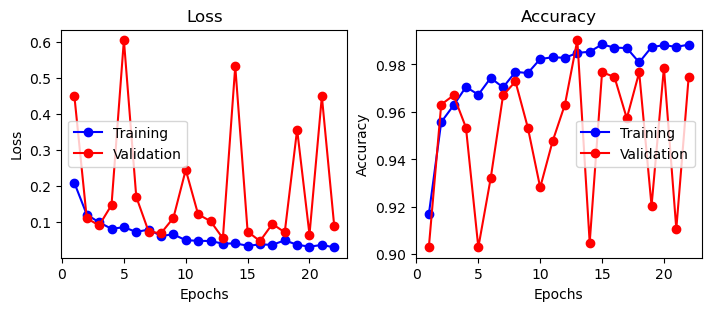

In [14]:
loss = history.history['loss']
val_loss = history.history['val_loss']
accuracy = history.history['acc']
val_accuracy = history.history['val_acc']

_, ax = plt.subplots(1, 2, figsize=(7, 3), constrained_layout=True)
epoch_list = range(1, len(loss) + 1)

ax[0].plot(epoch_list, loss, 'bo-', label='Training')
ax[0].plot(epoch_list, val_loss, 'ro-', label='Validation')
ax[0].set_title('Loss')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss')
# ax[0].set_ylim(0, 1)
ax[0].legend()

ax[1].plot(epoch_list, accuracy, 'bo-', label='Training')
ax[1].plot(epoch_list, val_accuracy, 'ro-', label='Validation')
ax[1].set_title('Accuracy')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Accuracy')
# ax[1].set_ylim(0, 1)
ax[1].legend()

plt.show()

In [15]:
from pathlib import Path

# restore_best_weights may have swapped in another epoch's weights, so check again
n_lens, n_val, spread = collapse_check.lens_predictions(model)
print(f'{n_lens}/{n_val} validation cutouts predicted lens, logit std {spread:.3g}')
if n_lens in (0, n_val):
    raise RuntimeError('the model predicts one class for every validation cutout, so it was not saved')

model_output_dir = Path("data") / "models"
model_output_dir.mkdir(parents=True, exist_ok=True)
model_path = model_output_dir / "roman_v1.keras"
print(f"Writing to {model_path}...")
model.save(str(model_path))

49/515 validation cutouts predicted lens, logit std 4.14
Writing to data/models/roman_v1.keras...
